# PERCEPTRÓN MULTICAPA Y RED CONVOLUCIONAL PARA  "FASHION-MNIST"

# PREPARACIÓN

**Atención, activar el modo GPU en "editar" -> "configuración del cuaderno" de cara al entrenamiento de la red convolucional**

CARGAMOS LAS LIBRERÍAS

In [1]:
from tensorflow import keras
from keras.models import Sequential
from keras import datasets, layers, models
from keras.utils import plot_model
from keras.optimizers import SGD

2026-04-24 15:18:39.687724: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Cargamos los datos

In [3]:
fashion = keras.datasets.fashion_mnist
(train_images,y_train),(test_images,y_test) = fashion.load_data()

# CODIFICAMOS LAS ETIQUETAS EN ESTILO "ONE-HOT"
num_classes = 10
train_labels = keras.utils.to_categorical(y_train, num_classes)
test_labels = keras.utils.to_categorical(y_test, num_classes)

#ESTANDARIZAMOS LAS IMÁGENES. Cada píxel tiene una tonalidad de gris que se representa desde 0 (blanco) a 255(negro)
train_images = train_images / 255.0
test_images = test_images / 255.0

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress','Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Comprobamos la codificación de las etiquetas

In [4]:
print(y_test[0])
print(train_labels[0])

9
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


Vemos el tamaño del conjunto de datos y la forma de las imágenes

In [5]:
print(train_images.shape)
print(test_images.shape)

(60000, 28, 28)
(10000, 28, 28)


##Dibujamos unas imagen del conjunto de datos

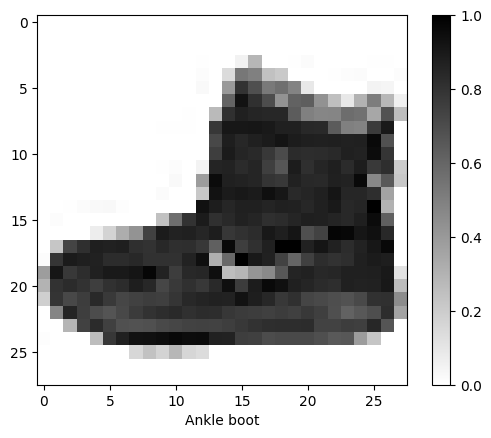

In [6]:
plt.figure()
plt.imshow(train_images[0], cmap=plt.cm.binary)
plt.colorbar()
plt.grid(False)
plt.xlabel(class_names[y_train[0]])

plt.show()

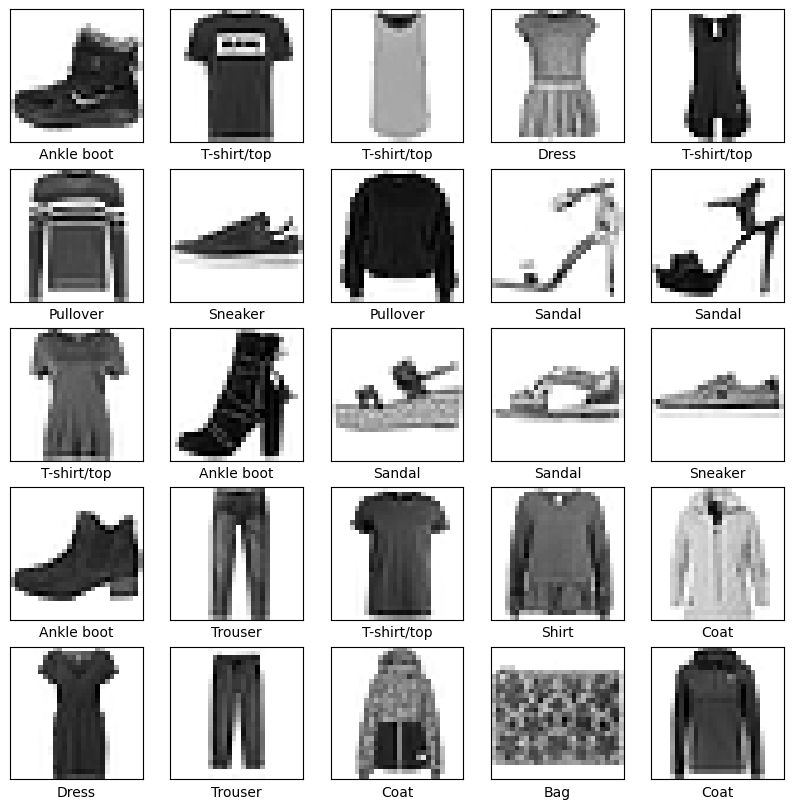

In [7]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[y_train[i]])
plt.show()

# RED CONVOLUCIONAL

In [10]:
def cnn_model():
  model= keras.Sequential(
      [
          layers.Input(shape=(28,28,1)), #Tenemos que añadir el canal
          layers.Conv2D(filters = 8, kernel_size=(3, 3), activation="relu"),
          layers.MaxPooling2D(pool_size=(2, 2)),
          layers.Flatten(),
          layers.Dense(num_classes, activation="softmax"),
      ]
  )
  return model

model = cnn_model()

In [11]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1352)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        13,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,610 (53.16 KB)

 Trainable params: 13,610 (53.16 KB)

 Non-trainable params: 0 (0.00 B)

### Dibujamos la evolución del entrenamiento

In [12]:
def plot_hist(history):
  plt.plot(history.history['accuracy'], label='accuracy')
  plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
  plt.xlabel('Epoch')
  plt.ylabel('Accuracy')
  plt.ylim([0.5, 1])
  plt.legend(loc='lower right')
  plt.show()



In [13]:
#CONFIGURAMOS LOS HIPERPARÁMETROS
model = cnn_model()
batch_size = 32
epochs = 10
loss = "categorical_crossentropy"
optimizer = SGD(learning_rate=0.01)

#ENTRENAMOS
model.compile(loss=loss, optimizer=optimizer, metrics=["accuracy"])
history = model.fit(train_images, train_labels, batch_size=batch_size, epochs=epochs,
          validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.7400 - loss: 0.7412 - val_accuracy: 0.8046 - val_loss: 0.5417
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8154 - loss: 0.5149 - val_accuracy: 0.8212 - val_loss: 0.5074
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8337 - loss: 0.4714 - val_accuracy: 0.8113 - val_loss: 0.5016
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8451 - loss: 0.4428 - val_accuracy: 0.8299 - val_loss: 0.4794
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8544 - loss: 0.4190 - val_accuracy: 0.8379 - val_loss: 0.4566
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8605 - loss: 0.4027 - val_accuracy: 0.8554 - val_loss: 0.4163
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8652 - loss: 0.3893 - val_accuracy: 0.8619 - val_loss: 0.4003
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8690 - loss: 0.3782 -

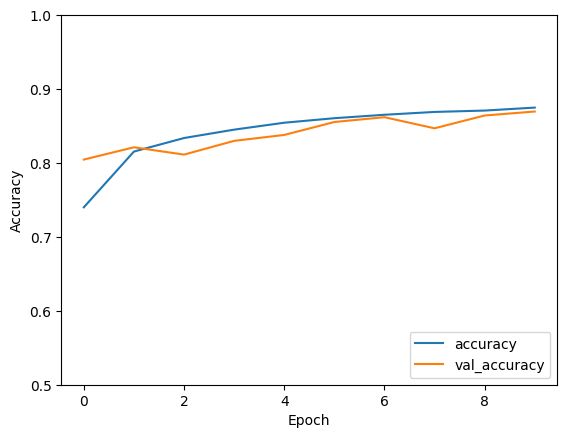

In [14]:
plot_hist(history)

In [15]:
test_loss, test_accuracy = model.evaluate(test_images,  test_labels, verbose=0)
print("La precisión es: ", np.round(test_accuracy,3))

La precisión es:  0.87


## Probamos un entrenamiento mucho más largo

In [16]:
#CONFIGURAMOS LOS HIPERPARÁMETROS
model = cnn_model()
batch_size = 32
epochs = 40
loss = "categorical_crossentropy"
optimizer = SGD(learning_rate=0.01)

#ENTRENAMOS
model.compile(loss=loss, optimizer=optimizer, metrics=["accuracy"])
history = model.fit(train_images, train_labels, batch_size=batch_size, epochs=epochs,
          validation_data=(test_images, test_labels))

Epoch 1/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.7494 - loss: 0.7201 - val_accuracy: 0.8059 - val_loss: 0.5433
Epoch 2/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8175 - loss: 0.5154 - val_accuracy: 0.8291 - val_loss: 0.4920
Epoch 3/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8361 - loss: 0.4685 - val_accuracy: 0.8336 - val_loss: 0.4677
Epoch 4/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8470 - loss: 0.4369 - val_accuracy: 0.8473 - val_loss: 0.4422
Epoch 5/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8573 - loss: 0.4132 - val_accuracy: 0.8530 - val_loss: 0.4239
Epoch 6/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8630 - loss: 0.3962 - val_accuracy: 0.8578 - val_loss: 0.4136
Epoch 7/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8673 - loss: 0.3832 - val_accuracy: 0.8633 - val_loss: 0.3979
Epoch 8/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8708 - loss: 0.3729 -

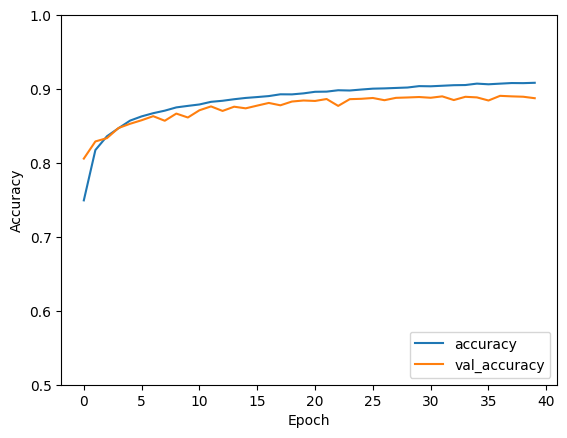

In [17]:
plot_hist(history)